# El problema de inmersión: si existe un generador y cuál usar

**Pregunta:** ¿Es la matriz agrupada de S&P a un año la exponencial de un generador válido y, si no lo es, qué reparación mantiene la exponencial del generador más cerca de la matriz y qué hace la elección a una PD a cinco años?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 02 de este tema (la matriz agrupada y el generador EM)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook puedes:

- decir qué pregunta el problema de inmersión (¿es una matriz a un año la exponencial de un generador?) y por qué importa para una PD a un horizonte distinto de un año;
- correr las verificaciones de Israel, Rosenthal y Wei sobre una matriz real y leer cada una: la convergencia de la serie del logaritmo, las tres condiciones que excluyen un generador exacto, la monotonía estocástica;
- calcular el logaritmo de la matriz por su serie, encontrar sus entradas negativas fuera de la diagonal y repararlas con los ajustes diagonal, ponderado y de Jarrow-Lando-Turnbull;
- comparar las reparaciones y el generador EM por la distancia L1 de la exponencial a la matriz, y por la PD que cada uno da a uno y cinco años;
- leer las nueve distancias que imprimen Israel et al. junto al recálculo del motor, y decir cuál no se reproduce y por qué.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.transitions import embedding, estimators
from riskvalidation.transitions.em import em_generator
from scipy.linalg import expm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Dos archivos versionados del caso C04:

- `data/derived/C04/sp.json`: la matriz anual agrupada de S&P del notebook 02 (`outputs.pooled.matrix`, retiradas removidas, siete grados e incumplimiento) y lo que el caso calculó de ella: `outputs.embedding` (los diagnósticos) y `outputs.generators` (los generadores diagonal, ponderado, JLT y EM con sus distancias L1 y sus PD a uno y cinco años). Fuente: ESMA CEREP (clase de licencia `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/).
- `data/derived/C04/published.json`: las distancias L1 que imprimen Israel, Rosenthal y Wei para tres matrices de agencias, cada una con el valor que recalcula el motor. Las matrices del artículo no están versionadas (el artefacto guarda solo las distancias), así que esta parte del notebook lee la comparación y no puede repetirla.

La celda siguiente carga ambos archivos y nombra las cohortes con que se construye la matriz agrupada.

In [2]:
# Cargar los dos artefactos (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
load = lambda name: json.loads((C04 / name).read_text(encoding="utf-8"))
sp, published = load("sp.json"), load("published.json")
out = sp["outputs"]
states = out["states"]
cohorts = out["cohorts"]

print("estados:", states)
print("cohortes anuales:", len(cohorts), "| motor que calculó los artefactos:",
      sp["provenance"]["riskvalidation_version"])

estados: ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC-C', 'D']
cohortes anuales: 26 | motor que calculó los artefactos: 1.0.1


## Método

### Paso 0: la matriz agrupada a un año

Todo lo que sigue parte de una matriz, la matriz agrupada a un año de S&P del notebook 02: las 26 tablas anuales de conteos sumadas, con las calificaciones retiradas quitadas año por año y cada fila dividida por su total. La celda siguiente la reconstruye con el `pooled_cohort` del motor e imprime la diagonal, la probabilidad de quedarse en el grado durante un año (el incumplimiento es absorbente, así que su entrada es uno).

In [3]:
# Agrupar las 26 tablas anuales en la matriz a un año sobre la que trabaja el resto del notebook
tables = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in cohorts]
gone = [np.append(np.array(c["withdrawn"], dtype=float), 0.0) for c in cohorts]
P = estimators.pooled_cohort(tables, gone, treatment="exclude")["matrix"]

print("matriz:", P.shape)
print("probabilidad de quedarse un año:", ", ".join(f"{s} {v:.4f}" for s, v in zip(states, np.diag(P))))

matriz: (8, 8)
probabilidad de quedarse un año: AAA 0.8227, AA 0.8901, A 0.9399, BBB 0.9294, BB 0.8735, B 0.8692, CCC-C 0.7148, D 1.0000


### Paso 1: ¿puede esta matriz tener un generador?

Una matriz de calificaciones $P$ se observa durante un año, pero un banco necesita PD a tres o cinco años, y un modelo en tiempo continuo necesita un **generador** $Q$: entradas fuera de la diagonal no negativas (tasas de movimiento), filas que suman cero, con $\exp(Q) = P$. El problema de inmersión pregunta si existe tal $Q$. Israel, Rosenthal y Wei (2001) dan tres herramientas, todas en el `embedding_diagnostics` del motor:

- **Teorema 1.** Con $S = \max\{(a-1)^2 + b^2 : a + bi \text{ un valor propio de } P\}$, si $S < 1$ la serie $\tilde Q = (P - I) - \tfrac12 (P-I)^2 + \tfrac13 (P-I)^3 - \dots$ converge y $\exp(\tilde Q) = P$ exactamente, con filas que suman cero. Teorema 2: si todo $p_{ii} > 1/2$ entonces $S < 1$, y el generador, si existe, es único.
- **Teorema 3.** No existe un generador exacto si (a) $\det P \le 0$, (b) $\det P > \prod_i p_{ii}$, o (c) algún estado $j$ es alcanzable desde $i$ mientras $p_{ij} = 0$.
- **Lema 1** (Jarrow, Lando y Turnbull). La cadena es estocásticamente monótona cuando $\sum_{j \ge k} p_{ij}$ no decrece en $i$ para todo $k$: un grado peor nunca es más seguro.

La celda siguiente corre los diagnósticos y los imprime como tabla, con los pares de la condición (c) nombrados por sus estados.

In [4]:
# Correr los diagnósticos de inmersión de Israel, Rosenthal y Wei sobre la matriz agrupada
diag = embedding.embedding_diagnostics(P)
pairs = [f"{states[i]} a {states[j]}" for i, j in diag["theorem3_c"]]

print(f"S (Theorem 1): {diag['S']:.4f} | la serie converge: {diag['series_converges']}")
print(f"toda entrada diagonal sobre 1/2: {diag['all_diagonal_above_half']}")
print(f"det P = {diag['det']:.4f} | producto de la diagonal = {diag['prod_diagonal']:.4f}")
print("Theorem 3 (a) det <= 0:", diag["theorem3_a"], "| (b) det > prod p_ii:", diag["theorem3_b"])
print("Theorem 3 (c) alcanzable con p_ij = 0:", len(pairs), pairs)
print("un generador exacto está excluido:", diag["exact_generator_excluded"])
print("estocásticamente monótona:", diag["stochastically_monotone"],
      "|", len(diag["monotonicity_violations"]), "violaciones")

S (Theorem 1): 0.1209 | la serie converge: True
toda entrada diagonal sobre 1/2: True
det P = 0.3364 | producto de la diagonal = 0.3471
Theorem 3 (a) det <= 0: False | (b) det > prod p_ii: False
Theorem 3 (c) alcanzable con p_ij = 0: 6 ['AAA a BBB', 'AAA a BB', 'AAA a D', 'B a AAA', 'CCC-C a AAA', 'CCC-C a AA']
un generador exacto está excluido: True
estocásticamente monótona: False | 4 violaciones


Léelo así: S está bien bajo uno, así que la serie converge y la matriz tiene un generador candidato $\tilde Q$, y toda entrada diagonal supera 1/2, así que un generador, si lo hubiera, sería único. El determinante queda entre cero y el producto de la diagonal, así que las condiciones (a) y (b) no lo excluyen. La condición (c) sí, en seis pares: AAA alcanza BBB, BB y el incumplimiento en varios pasos y B y CCC-C alcanzan los grados superiores, mientras la matriz agrupada a un año tiene cero para cada uno de esos movimientos. Así que **no existe un generador exacto**, y la cadena además rompe la monotonía en cuatro celdas. Es la situación habitual con una matriz empírica. Lo que los diagnósticos no dan es el tamaño del daño: la pregunta pasa a ser qué generador válido usar y qué tan lejos queda su exponencial de la matriz.

### Paso 2: el logaritmo de la matriz por su serie

El `log_series` del motor suma la serie del Teorema 1 hasta que un término queda bajo $10^{-14}$ y además informa su distancia a `logm` de SciPy, que calcula el logaritmo principal con otro algoritmo. El resultado $\tilde Q$ es el único candidato, y es un generador solo si ninguna entrada fuera de la diagonal es negativa. La celda siguiente imprime cuántos términos necesitó, qué tan bien la exponencial de $\tilde Q$ devuelve $P$ y cuántas entradas fuera de la diagonal son negativas.

In [5]:
# Sumar la serie del logaritmo, exponenciarla de vuelta y contar las entradas negativas fuera de la diagonal
series = embedding.log_series(P)
q_tilde = series["generator"]
off = ~np.eye(len(states), dtype=bool)
negative = off & (q_tilde < -1e-12)
corner = np.unravel_index(np.argmin(np.where(off, q_tilde, 0.0)), q_tilde.shape)

print("términos sumados:", series["terms"], "| distancia a logm de SciPy:", f"{series['distance_to_logm']:.1e}")
print("mayor entrada de exp(Q~) - P:", f"{np.abs(expm(q_tilde) - P).max():.1e}")
print("entradas negativas fuera de la diagonal:", int(negative.sum()))
print("más negativa:", states[corner[0]], "a", states[corner[1]], round(float(q_tilde[corner]), 4))
print("Q~ es un generador:", embedding.is_generator(q_tilde))

términos sumados: 28 | distancia a logm de SciPy: 1.7e-15
mayor entrada de exp(Q~) - P: 1.4e-15
entradas negativas fuera de la diagonal: 9
más negativa: CCC-C a BB -0.0036
Q~ es un generador: False


La celda siguiente dibuja dónde están las entradas negativas, una celda de la matriz por cuadrado, en milésimas de unidad de tasa por año.

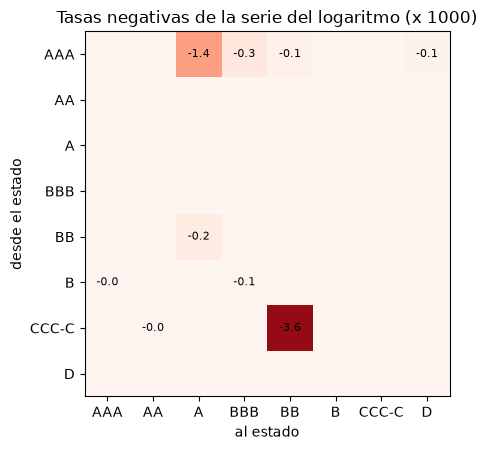

In [6]:
# Dibujar las entradas negativas fuera de la diagonal de Q~ (tasa por año por 1000), cero en el resto
shown = np.where(negative, 1000 * q_tilde, 0.0)
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.imshow(shown, cmap="Reds_r", vmin=-4, vmax=0)
for i, j in zip(*np.nonzero(negative)):
    ax.text(j, i, f"{shown[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(states)))
ax.set_xticklabels(states)
ax.set_yticks(range(len(states)))
ax.set_yticklabels(states)
ax.set_xlabel("al estado")
ax.set_ylabel("desde el estado")
ax.set_title("Tasas negativas de la serie del logaritmo (x 1000)")
fig.tight_layout()
plt.show()

La serie converge, queda a 1,7e-15 del logaritmo de SciPy y devuelve la matriz a 1,4e-15, así que la aritmética es sana; el problema es el modelo. Nueve entradas fuera de la diagonal son negativas, y ocho están en las filas de AAA, B y CCC-C, las filas que la condición (c) señaló: donde la matriz registra un movimiento como imposible en un año, el logaritmo responde con una tasa negativa para uno vecino. La figura muestra que el daño está concentrado: la mayor es CCC-C a BB con -3,6 por mil, luego AAA a A con -1,4, y las otras siete son menores que 0,4 en valor absoluto. No muestra cuánto cuesta una reparación, que es el paso siguiente.

### Paso 3: tres maneras de repararlo

Cada reparación quita las entradas negativas y mantiene las sumas de fila en cero, al precio de $\exp(Q) \neq P$:

- **Ajuste diagonal**, ecuación (2): $q_{ij} = \max(\tilde q_{ij}, 0)$ para $j \ne i$ y $q_{ii} = \tilde q_{ii} + \sum_{j \ne i} \min(\tilde q_{ij}, 0)$. La masa negativa va a la diagonal.
- **Ajuste ponderado**, ecuación (2'): las entradas negativas se llevan a cero y su total $B_i = \sum_{j \ne i} \max(-\tilde q_{ij}, 0)$ se descuenta de las entradas del signo correcto en proporción a su tamaño, $q_{ij} = \tilde q_{ij} - B_i |\tilde q_{ij}| / G_i$ con $G_i = |\tilde q_{ii}| + \sum_{j \ne i} \max(\tilde q_{ij}, 0)$.
- **JLT**, ecuación (3) de Jarrow, Lando y Turnbull, que no usa la serie: supone a lo más una transición al año, $q_{ii} = \log p_{ii}$ y $q_{ij} = p_{ij} \log(p_{ii}) / (p_{ii} - 1)$.

Israel et al. miden cada reparación con la distancia L1 $\sum_{ij} |P - \exp(Q)|_{ij}$.

La celda siguiente sigue la peor fila, CCC-C, a través de las tres fórmulas y luego imprime, para cada reparación, si el resultado es un generador válido y su distancia L1.

In [7]:
# Las tres reparaciones, la fila CCC-C a través de cada una y la validez y la distancia L1 de cada resultado
q_diag = embedding.diagonal_adjustment(q_tilde)
q_weighted = embedding.weighted_adjustment(q_tilde)
q_jlt = embedding.jlt_generator(P)
repairs = {"Q~ (serie)": q_tilde, "diagonal (2)": q_diag, "ponderado (2')": q_weighted, "JLT (3)": q_jlt}
row = len(states) - 2

print(f"{'':20s}" + "".join(f"{s:>9s}" for s in states))
for label, q in repairs.items():
    print(f"{label:20s}" + "".join(f"{v:9.5f}" for v in q[row]))
print(f"{'':20s}{'generador válido':>20s}{'distancia L1':>16s}")
for label, q in list(repairs.items())[1:]:
    print(f"{label:20s}{str(embedding.is_generator(q)):>20s}{embedding.l1_distance(P, q):16.5f}")

                          AAA       AA        A      BBB       BB        B    CCC-C        D
Q~ (serie)            0.00000 -0.00003  0.00059  0.00028 -0.00361  0.25561 -0.34684  0.09400
diagonal (2)          0.00000  0.00000  0.00059  0.00028  0.00000  0.25561 -0.35048  0.09400
ponderado (2')        0.00000  0.00000  0.00058  0.00027  0.00000  0.25428 -0.34865  0.09351
JLT (3)               0.00000  0.00000  0.00063  0.00032  0.00410  0.23570 -0.33572  0.09497
                        generador válido    distancia L1
diagonal (2)                        True         0.00998
ponderado (2')                      True         0.00980
JLT (3)                             True         0.09891


La fila CCC-C muestra qué hace cada fórmula con la masa negativa de -0,0036 en BB: el ajuste diagonal la mueve a la diagonal y deja intacta cualquier otra entrada, el ajuste ponderado la reparte entre las entradas del signo correcto en proporción a su tamaño, y JLT parte de nuevo de la matriz y da a BB una tasa positiva de 0,0041 porque supone a lo más una transición por año. Las tres son generadores válidos. La tabla de L1 dice que las reparaciones diagonal y ponderada mantienen su exponencial a unos 0,01 de la matriz, la ponderada algo más cerca, y que JLT queda diez veces más lejos. La tabla no dice cuál de ellas es la correcta, solo cuánto se aleja cada una de lo observado.

### Paso 4: el generador EM

El generador EM del notebook 02 es un cuarto candidato con otra lógica. No repara la matriz: maximiza la verosimilitud de las 26 tablas anuales de conteos (Bladt y Sorensen, 2005; Smith y dos Reis, 2018) y es un generador válido por construcción. La celda siguiente corre el `em_generator` del motor sobre las mismas tablas y mide su distancia a la matriz agrupada, que no es lo que optimiza.

In [8]:
# Correr el generador EM sobre las 26 tablas y medir su distancia L1 a la matriz agrupada
em = em_generator([{"counts": t, "dt": 1.0} for t in tables])
q_em = em["generator"]

print("iteraciones:", em["iterations"], "| convergió:", em["converged"])
print("generador válido:", embedding.is_generator(q_em))
print("distancia L1 de exp(Q) a P:", round(embedding.l1_distance(P, q_em), 5))

iteraciones: 116 | convergió: True
generador válido: True
distancia L1 de exp(Q) a P: 0.01063


La celda siguiente dibuja la distancia L1 de los cuatro candidatos a la matriz.

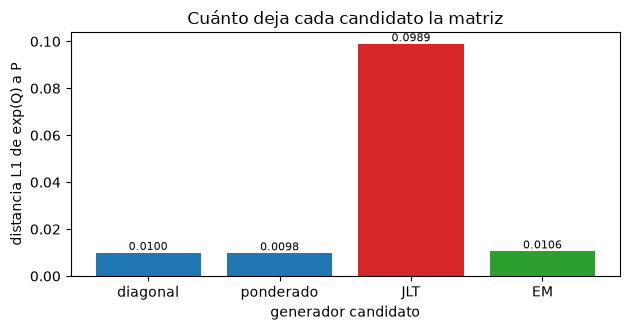

In [9]:
# Dibujar la distancia L1 de exp(Q) a P para los cuatro generadores candidatos
candidates = {"diagonal": q_diag, "ponderado": q_weighted, "JLT": q_jlt, "EM": q_em}
distance = [embedding.l1_distance(P, q) for q in candidates.values()]
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(list(candidates), distance, color=["tab:blue", "tab:blue", "tab:red", "tab:green"])
for k, v in enumerate(distance):
    ax.text(k, v, f"{v:.4f}", ha="center", va="bottom", fontsize=8)
ax.set_xlabel("generador candidato")
ax.set_ylabel("distancia L1 de exp(Q) a P")
ax.set_title("Cuánto deja cada candidato la matriz")
fig.tight_layout()
plt.show()

La reparación diagonal (0,00998), la ponderada (0,00980) y el generador EM (0,01063) están a menos de diez por ciento entre sí, y JLT (0,0989) es de otro orden de magnitud. EM no es el más cercano aunque sea el único candidato que usa los conteos originales en lugar de la matriz agrupada: optimiza la verosimilitud de las tablas anuales y no la distancia a su agrupación. Las barras no pueden decir si una distancia de 0,01 importa, porque una distancia en la matriz a un año no es una distancia en una PD; el paso siguiente la convierte en el número que usa un validador.

### Paso 5: lo que cambia la elección, la PD a uno y cinco años

Un generador da la PD a cualquier horizonte $t$ como la columna de incumplimiento de $\exp(tQ)$. El estimador de cohorte no tiene generador, así que su PD a cinco años es la matriz elevada a la quinta.

La celda siguiente calcula, para AAA, B y CCC-C, la PD a uno y cinco años de cada candidato y de la matriz misma.

In [10]:
# La columna de incumplimiento a uno y cinco años para cada generador y la matriz a la quinta potencia
grades_shown = (0, 5, 6)
p5 = np.linalg.matrix_power(P, 5)
header = "".join(f"{states[g] + ' 1y':>11s}{states[g] + ' 5y':>11s}" for g in grades_shown)
print(f"{'':12s}" + header)
print(f"{'P^5':12s}" + "".join(f"{100 * P[g, -1]:10.3f}%{100 * p5[g, -1]:10.3f}%" for g in grades_shown))
for name, q in candidates.items():
    one, five = expm(q)[:, -1], expm(5 * q)[:, -1]
    print(f"{name:12s}" + "".join(f"{100 * one[g]:10.3f}%{100 * five[g]:10.3f}%" for g in grades_shown))

                 AAA 1y     AAA 5y       B 1y       B 5y   CCC-C 1y   CCC-C 5y
P^5              0.000%     0.102%     1.173%     8.214%     8.068%    25.298%
diagonal         0.007%     0.127%     1.173%     8.192%     8.054%    25.145%
ponderado        0.007%     0.126%     1.171%     8.176%     8.019%    25.088%
JLT              0.007%     0.138%     1.466%     9.063%     8.217%    26.183%
EM               0.007%     0.123%     1.173%     8.214%     8.062%    25.266%


La celda siguiente dibuja la PD a cinco años de AAA y de CCC-C bajo cada candidato, con la matriz a la quinta potencia como línea punteada.

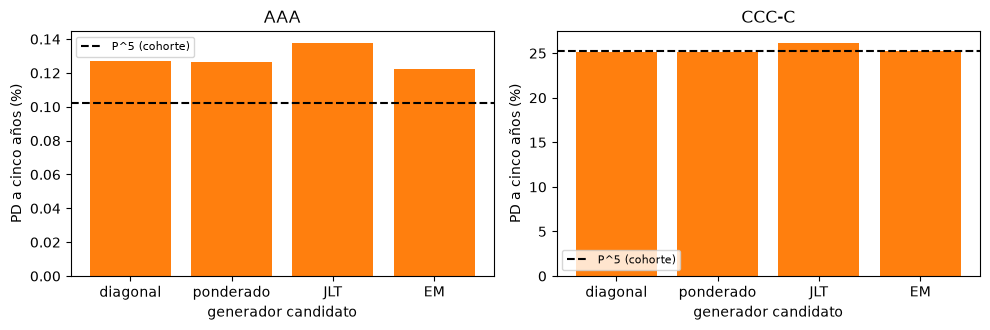

In [11]:
# Dibujar la PD a cinco años de AAA y CCC-C bajo cada candidato, frente a la matriz a la quinta potencia
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, g in zip(axes, (0, 6)):
    values = [100 * expm(5 * q)[g, -1] for q in candidates.values()]
    ax.bar(list(candidates), values, color="tab:orange")
    ax.axhline(100 * p5[g, -1], color="black", linestyle="--", label="P^5 (cohorte)")
    ax.set_xlabel("generador candidato")
    ax.set_ylabel("PD a cinco años (%)")
    ax.set_title(states[g])
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

A un año los generadores dan a B y CCC-C la PD de la matriz con una diferencia de hasta 0,05 puntos para los candidatos diagonal, ponderado y EM, y 1,47% frente a 1,17% para B bajo JLT. A cinco años la dispersión se abre: CCC-C es 25,30% por la matriz a la quinta potencia, 25,15% por la reparación diagonal, 25,09% por la ponderada, 25,27% por EM y 26,18% por JLT, un punto de PD que es parte de la respuesta y no ruido. AAA muestra el otro efecto: la matriz le da exactamente cero a un año, y todo generador le da una PD positiva pequeña que crece a cerca de 0,12% a 0,14% a cinco años, porque un generador encadena los movimientos raros a lo largo de la escala. Los paneles no dicen cuál de estas es la PD verdadera; solo una verdad conocida puede, como en el notebook 02.

### Paso 6: frente a las distancias impresas por Israel et al.

El artículo imprime la distancia L1 de cada reparación en tres matrices de agencias (S&P 1981 a 1991, Moody's 1980 a 1998, S&P 1999), nueve números. El caso los recalcula desde las matrices impresas y versiona ambos, con una regla: un valor recalculado coincide cuando queda a media unidad del último dígito de lo impreso.

La celda siguiente imprime las nueve filas, con el recálculo del motor y el veredicto de la regla, y la explicación de la que no coincide.

In [12]:
# Las nueve distancias impresas junto al recálculo del motor guardado en el artefacto
irw = published["outputs"]["irw"]
print(f"{'matriz':20s}{'reparación':>12s}{'impreso':>12s}{'recalculado':>14s}{'coincide':>10s}")
for r in irw["rows"]:
    print(f"{r['matrix']:20s}{r['method']:>12s}{r['printed']:12.6f}{r['recomputed']:14.6f}{str(r['agrees']):>10s}")
miss = [r for r in irw["rows"] if not r["agrees"]][0]
print("la que no coincide:", miss["matrix"], miss["method"], "| impreso", miss["printed"],
      "| desde el generador JLT impreso:", round(irw["jlt_from_printed_generator"], 4))

matriz                reparación     impreso   recalculado  coincide
S&P 1981-1991                jlt    0.116900      0.116477     False
S&P 1981-1991           diagonal    0.002736      0.002736      True
S&P 1981-1991           weighted    0.002686      0.002686      True
Moody's 1980-1998            jlt    0.100047      0.100047      True
Moody's 1980-1998       diagonal    0.001401      0.001401      True
Moody's 1980-1998       weighted    0.001371      0.001371      True
S&P 1999                     jlt    0.103516      0.103516      True
S&P 1999                diagonal    0.001096      0.001096      True
S&P 1999                weighted    0.001088      0.001088      True
la que no coincide: S&P 1981-1991 jlt | impreso 0.1169 | desde el generador JLT impreso: 0.1169


Ocho de las nueve distancias se reproducen hasta los dígitos impresos. La novena, JLT sobre S&P 1981 a 1991, imprime 0,1169 donde la ecuación (3) sobre la matriz impresa da 0,1165, y la discrepancia es la aritmética del propio artículo: 0,1169 sale del generador JLT impreso de cuatro dígitos, no de la matriz impresa, y partiendo de ese generador el motor también obtiene 0,1169. El caso informa la brecha y lleva la explicación en lugar de ajustar un número. Las matrices del artículo no están versionadas, solo estas distancias, así que este paso lee la comparación y no puede volver a correrla.

## Resultados

**Respuesta:** no. La matriz agrupada de S&P no tiene un generador exacto: S = 0,121 está bajo uno, pero la condición (c) del Teorema 3 se cumple en seis pares y la matriz rompe la monotonía en cuatro celdas; la serie del logaritmo, exacta a 1,4e-15, tiene nueve entradas negativas fuera de la diagonal, la más negativa CCC-C a BB (-0,0036). La reparación que mantiene su exponencial más cerca de la matriz es el ajuste ponderado, con una distancia L1 de 0,00980, por delante de la reparación diagonal (0,00998), el generador EM (0,01063) y JLT (0,0989). La elección mueve una PD a cinco años: CCC-C es 25,30% por la matriz a la quinta potencia y 26,18% por JLT.

- **Sin generador exacto.** El determinante, 0,3364, queda entre cero y el producto de la diagonal, 0,3471, así que las condiciones (a) y (b) del Teorema 3 no excluyen uno, y toda entrada diagonal supera 1/2.
- **La PD a cinco años depende de la reparación.** CCC-C es 25,15% bajo la reparación diagonal, 25,09% bajo la ponderada y 25,27% bajo EM; AAA pasa de exactamente 0 a un año en la matriz a 0,007% bajo todo generador.
- **Frente a lo impreso.** Ocho de las nueve distancias L1 que imprimen Israel et al. se reproducen. La novena, JLT sobre S&P 1981 a 1991, imprime 0,1169 donde la ecuación (3) sobre la matriz impresa da 0,1165; partiendo del generador impreso de cuatro dígitos del artículo la misma distancia es 0,1169.

Lo que este notebook no muestra: si el modelo de Markov se ajusta siquiera a los datos (notebook 04), ni un generador con condicionamiento macroeconómico (notebook 08).

## Resumen

- Una matriz a un año tiene un generador exacto solo si la serie del logaritmo converge, ninguna condición del Teorema 3 lo excluye y el resultado tiene entradas no negativas fuera de la diagonal; una matriz empírica rara vez lo cumple.
- Las reparaciones diagonal y ponderada y el generador EM quedan cerca de la matriz; JLT queda diez veces más lejos aquí.
- El generador es parte de la PD a un horizonte mayor: la PD a cinco años de CCC-C se mueve cerca de un punto entre los candidatos, y un grado con PD cero a un año recibe una positiva.
- Un recálculo que no coincide con un impreso se informa con su explicación, nunca se ajusta.

**Qué probar después.** Calcula la serie del logaritmo de la matriz de la cohorte 2000 del notebook 01 y mira cuántas entradas negativas da un solo año; luego lee el notebook 04.

## Referencias

- ESMA, publicación CEREP de calificaciones y transiciones de agencias calificadoras. https://registers.esma.europa.eu/cerep-publication/
- Israel, R. B., Rosenthal, J. S. y Wei, J. Z. (2001), Finding generators for Markov chains via empirical transition matrices, with applications to credit ratings, Mathematical Finance 11(2), 245-265, Teoremas 1 a 3, Lema 1 y ecuaciones (2), (2') y (3). https://doi.org/10.1111/1467-9965.00114
- Jarrow, R. A., Lando, D. y Turnbull, S. M. (1997), A Markov model for the term structure of credit risk spreads, Review of Financial Studies 10(2), según lo cita el motor para la ecuación (3) y el Lema 1.
- Bladt, M. y Sorensen, M. (2005), Journal of the Royal Statistical Society B 67(3), y Smith, A. y dos Reis, G. (2018), Quantitative Finance, doi 10.1080/14697688.2017.1383627, para el generador EM.